<a href="https://colab.research.google.com/github/solomon-211/formative-3-probability-gradient-descent/blob/solomon/gradient_descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formative 3, Parts 3 and 4: Gradient Descent

Linear regression model in matrix form: **ŷ = Xm + b**

- X = [[1, 3], [4, 10]], y = [5, 6]ᵀ
- Initial m = [−1, 2]ᵀ, initial b = [1, 1]ᵀ
- Learning rate α = 0.01 (assumed, not given in the assignment)
- Number of updates = 3 (one per group member)

**Gradients (derived by hand in Part 3, chain rule J → e → ŷ → (m, b)):**

- ∂J/∂m = (2/n) Xᵀ(ŷ − y)
- ∂J/∂b = (2/n) (ŷ − y)

**Update rules:** m ← m − α ∂J/∂m, b ← b − α ∂J/∂b

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

## 1. Data and hyperparameters

In [ ]:
X = np.array([[1.0, 3.0],
              [4.0, 10.0]])
y = np.array([5.0, 6.0])
m_init = np.array([-1.0, 2.0])
b_init = np.array([1.0, 1.0])

alpha = 0.01        # learning rate (assumed)
num_updates = 3     # Number of updates from group members

## 2. Building blocks

Each function does one job, mirrors one step of the hand calculation, and is reused in every iteration.

In [ ]:
def predict(X, m, b):
    """Predictions: y_hat = Xm + b"""
    return X @ m + b


def compute_error(y_hat, y):
    """Prediction error: e = y_hat - y"""
    return y_hat - y


def compute_cost(e):
    """MSE cost: J = (1/n) e^T e"""
    return (1 / len(e)) * (e @ e)


def compute_gradients(X, e):
    """Hand-derived gradients: dJ/dm = (2/n) X^T e, dJ/db = (2/n) e"""
    n = len(e)
    dJ_dm = (2 / n) * X.T @ e
    dJ_db = (2 / n) * e
    return dJ_dm, dJ_db


def update_params(m, b, dJ_dm, dJ_db, alpha):
    """Gradient descent step: parameter = parameter - alpha * gradient"""
    return m - alpha * dJ_dm, b - alpha * dJ_db

## 3. SciPy: a function that accepts an equation and computes its derivative

`compute_derivative` takes any function `f(params) -> scalar` and a point, and returns the gradient at that point using SciPy's numerical differentiation. We pass in our cost function as the equation and use the result to check the hand-derived gradients.

In [ ]:
def compute_derivative(equation, point):
    """Numerical derivative (gradient) of `equation` at `point`, using SciPy."""
    return approx_fprime(point, equation, epsilon=1e-7)


def make_cost_equation(X, y):
    """Return J as a function of one vector params = [m1, m2, b1, b2]
    so that SciPy can differentiate it."""
    def cost_equation(params):
        m, b = params[:2], params[2:]
        return compute_cost(compute_error(predict(X, m, b), y))
    return cost_equation


cost_equation = make_cost_equation(X, y)

## 4. Gradient descent loop

Every calculation step is printed: ŷ, e, J, both gradients, the SciPy check, and the new m and b.

In [ ]:
def run_gradient_descent(X, y, m, b, alpha, num_updates):
    m_history, b_history, cost_history = [m.copy()], [b.copy()], []

    for i in range(1, num_updates + 1):
        print(f"\n===== Update {i} =====")

        y_hat = predict(X, m, b)                      # Step 1: predictions
        e = compute_error(y_hat, y)                   # Step 2: error
        J = compute_cost(e)                           # Step 3: cost
        dJ_dm, dJ_db = compute_gradients(X, e)        # Step 4: gradients

        scipy_grad = compute_derivative(cost_equation, np.concatenate([m, b]))
        assert np.allclose(scipy_grad, np.concatenate([dJ_dm, dJ_db]), atol=1e-4)

        m, b = update_params(m, b, dJ_dm, dJ_db, alpha)   # Step 5: update

        print("y_hat =", y_hat)
        print("e     =", e)
        print("J     =", J)
        print("dJ/dm =", dJ_dm)
        print("dJ/db =", dJ_db)
        print("SciPy gradient [dm1, dm2, db1, db2] =", np.round(scipy_grad, 4))
        print("new m =", m)
        print("new b =", b)

        m_history.append(m.copy())
        b_history.append(b.copy())
        cost_history.append(J)

    # cost with the final m and b, so the cost list lines up with the m/b history
    cost_history.append(compute_cost(compute_error(predict(X, m, b), y)))
    return m, b, np.array(m_history), np.array(b_history), cost_history


m_final, b_final, m_history, b_history, cost_history = run_gradient_descent(
    X, y, m_init, b_init, alpha, num_updates)


===== Update 1 =====
y_hat = [ 6. 17.]
e     = [ 1. 11.]
J     = 61.0
dJ/dm = [ 45. 113.]
dJ/db = [ 1. 11.]
SciPy gradient [dm1, dm2, db1, db2] = [ 45. 113.   1.  11.]
new m = [-1.45  0.87]
new b = [0.99 0.89]

===== Update 2 =====
y_hat = [2.15 3.79]
e     = [-2.85 -2.21]
J     = 6.503300000000002
dJ/dm = [-11.69 -30.65]
dJ/db = [-2.85 -2.21]
SciPy gradient [dm1, dm2, db1, db2] = [-11.69 -30.65  -2.85  -2.21]
new m = [-1.3331  1.1765]
new b = [1.0185 0.9121]

===== Update 3 =====
y_hat = [3.2149 7.3447]
e     = [-1.7851  1.3447]
J     = 2.4974000499999987
dJ/dm = [3.5937 8.0917]
dJ/db = [-1.7851  1.3447]
SciPy gradient [dm1, dm2, db1, db2] = [ 3.5937  8.0917 -1.7851  1.3447]
new m = [-1.369037  1.095583]
new b = [1.036351 0.898653]


## 5. Predictions using the final m and b

In [ ]:
final_y_hat = predict(X, m_final, b_final)
print("final m      =", m_final)
print("final b      =", b_final)
print("predictions  =", final_y_hat)
print("actual y     =", y)
print("final cost J =", cost_history[-1])

final m      = [-1.369037  1.095583]
final b      = [1.036351 0.898653]
predictions  = [2.954063 6.378335]
actual y     = [5. 6.]
final cost J = 2.1644977900969997


## 6. Plots

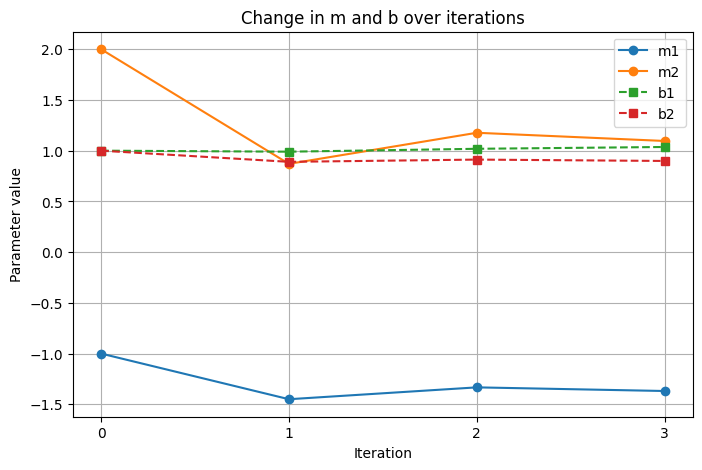

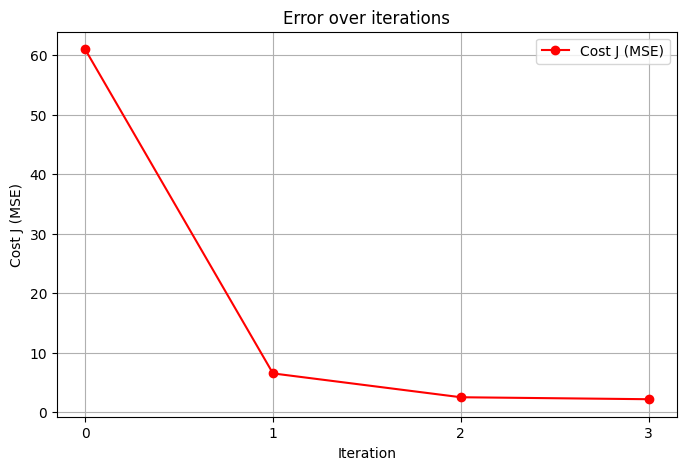

In [ ]:
def plot_history(steps, series, title, ylabel, filename):
    """Plot one or more series against iteration number and save the figure.
    `series` is a list of (values, label, style) tuples."""
    plt.figure(figsize=(8, 5))
    for values, label, style in series:
        plt.plot(steps, values, style, label=label)
    plt.xlabel("Iteration")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(list(steps))
    plt.legend()
    plt.grid(True)
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()


steps = range(num_updates + 1)

# Plot 1: m and b over iterations
plot_history(
    steps,
    [(m_history[:, 0], "m1", "o-"), (m_history[:, 1], "m2", "o-"),
     (b_history[:, 0], "b1", "s--"), (b_history[:, 1], "b2", "s--")],
    "Change in m and b over iterations", "Parameter value", "m_and_b_plot.png")

# Plot 2: error (cost) over iterations
plot_history(
    steps,
    [(cost_history, "Cost J (MSE)", "ro-")],
    "Error over iterations", "Cost J (MSE)", "error_plot.png")

## 7. Trend

- **m₂** falls from 2 to about 1.10, and **m₁** moves from −1 to about −1.37. The first update is the largest because the initial error was large.
- **b** changes only slightly, because its gradient (e) is much smaller than the gradient for m (Xᵀe).
- The first update overshoots (predictions go from too high to too low), so the error signs flip in Update 2. Later updates are smaller.
- The cost drops 61 → 6.50 → 2.50 → 2.16, so the parameters are moving in a direction that reduces the error.